# Hito 2 — Motor cinemático inverso (Pieper), trayectoria LSPB, Jacobiano, singularidades y dinámica 1R
### ABB IRB 120 · Robótica IMT-342 · UCB Tarija · Semestre II-2026

**Equipo:** Valeria Alejandra Hoyos Tovar
**Docente:** M.Sc. Ing. Bernardo Quiroga Turdera

Este notebook implementa un **pipeline continuo**: cada módulo consume la salida del anterior.

$$
T_d \;\xrightarrow{\text{Pieper}}\; \{q^{(k)}\}_{k=1}^{8} \;\xrightarrow{\text{FK}}\; \text{validación} \;\xrightarrow{\text{criterio}}\; q_0,\,q_f
\;\xrightarrow{\text{LSPB}}\; q(t),\dot q(t),\ddot q(t)
\;\xrightarrow{}\; J(q) \;\xrightarrow{}\; \text{singularidades} \;\xrightarrow{}\; \text{dinámica 1R} \;\xrightarrow{}\; \tau(t)
$$

**Convenciones y unidades (válidas en todo el notebook)**

| Magnitud | Unidad | Nota |
|---|---|---|
| Longitudes | m | cotas ABB 3HAC035960-005 (Hito 1) |
| Ángulos en código | rad | en tablas se muestran en grados |
| Tiempo | s | |
| Masa / torque | kg / N·m | $g = 9.81\ \text{m/s}^2$ |
| Orientación de poses | RPY fija (Z-Y-X): $R = R_z(\text{yaw})R_y(\text{pitch})R_x(\text{roll})$ | |
| Marco de la herramienta | TCP a 0.120 m sobre $z_6$ (Hito 1) | |



In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import json, platform

np.set_printoptions(precision=6, suppress=True, linewidth=120)
FIG_DIR = Path("figuras"); FIG_DIR.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "font.size": 9, "axes.titlesize": 10, "legend.fontsize": 8})
JOINT_COLORS = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd", "#8c564b"]
def savefig(fig, name):
    fig.savefig(FIG_DIR / f"{name}.pdf", bbox_inches="tight")
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight", dpi=150)f fmt_deg(q):
    return "[" + ", ".join(f"{v:8.2f}" for v in np.degrees(q)) + "]"

print("Python", platform.python_version(), "| NumPy", np.__version__, "| Matplotlib", plt.matplotlib.__version__)

Python 3.13.16 | NumPy 2.5.3 | Matplotlib 3.11.2


## 1. Modelo cinemático del IRB 120 (heredado del Hito 1)

Tabla D-H estándar validada en el Hito 1 contra ROS/TF ($\Delta E \approx 10^{-16}$ m).

| $i$ | $\theta_i$ | $d_i$ [m] | $a_i$ [m] | $\alpha_i$ |
|---|---|---|---|---|
| 1 | $q_1$ | 0.290 | 0 | $-\pi/2$ |
| 2 | $q_2-\pi/2$ | 0 | 0.270 | 0 |
| 3 | $q_3$ | 0 | 0.070 | $-\pi/2$ |
| 4 | $q_4$ | 0.302 | 0 | $+\pi/2$ |
| 5 | $q_5$ | 0 | 0 | $-\pi/2$ |
| 6 | $q_6$ | 0.072 | 0 | 0 |

$$ {}^{0}T_{TCP}(q) = {}^{0}T_1\,{}^{1}T_2\cdots{}^{5}T_6\;{}^{6}T_{TCP},\qquad {}^{6}T_{TCP} = \mathrm{Trans}(z,\,0.120). $$

**Límites articulares y velocidades máximas:** ABB *Product specification IRB 120* (3HAC035960-005), págs. 37 y 40, ya usados en el URDF del Hito 1.
No se inventa ningún dato: lo que el fabricante **no publica** (aceleraciones articulares máximas, masas e inercias por eslabón) se trata explícitamente como supuesto de diseño en las secciones 4 y 7.

In [ ]:
# ---- Geometría (m) — ABB 3HAC035960-005 p.15, igual que en el Hito 1 ----
D1, A2, A3, D4, D6 = 0.290, 0.270, 0.070, 0.302, 0.072
D_TCP = 0.120                                   # TCP de la pinza (Hito 1)

# ---- Límites (rad, rad/s) — ABB p.37 y p.40 (URDF Hito 1) ----
Q_MIN  = np.radians([-165, -110, -110, -160, -120, -400])
Q_MAX  = np.radians([ 165,  110,   70,  160,  120,  400])
QD_MAX = np.radians([ 250,  250,  250,  320,  320,  420])

def dh_matrix(theta, d, a, alpha):
    ct, st, ca, sa = np.cos(theta), np.sin(theta), np.cos(alpha), np.sin(alpha)
    return np.array([[ct, -st*ca,  st*sa, a*ct],
                     [st,  ct*ca, -ct*sa, a*st],
                     [0.0,    sa,     ca,    d],
                     [0.0,   0.0,    0.0,  1.0]])

def dh_params(q):
    q1, q2, q3, q4, q5, q6 = q
    return [(q1,           D1, 0.0, -np.pi/2),
            (q2 - np.pi/2, 0.0, A2,  0.0),
            (q3,           0.0, A3, -np.pi/2),
            (q4,           D4, 0.0,  np.pi/2),
            (q5,           0.0, 0.0, -np.pi/2),
            (q6,           D6, 0.0,  0.0)]

T_6_TCP = np.eye(4); T_6_TCP[2, 3] = D_TCP

def fk_frames(q):
    # Lista [0T0, 0T1, ..., 0T6]: se reutiliza en FK, Pieper (R03) y Jacobiano
    T = np.eye(4); frames = [T.copy()]
    for p in dh_params(q):
        T = T @ dh_matrix(*p); frames.append(T.copy())
    return frames

def fk(q, tcp=True):
    T06 = fk_frames(q)[-1]
    return T06 @ T_6_TCP if tcp else T06

# ---- Prueba de regresión contra los resultados validados del Hito 1 ----
ref_h1 = {"A": ([0, 0, 0, 0, 0, 0],        [0.374000000, 0.000000000, 0.630000000]),
          "B": ([20, -30, 25, 15, -20, 35], [0.213683251, 0.070991768, 0.649474138])}
for name, (qdeg, p_ref) in ref_h1.items():
    err = np.linalg.norm(fk(np.radians(qdeg), tcp=False)[:3, 3] - p_ref)
    print(f"Config {name}: |p_FK - p_Hito1| = {err:.2e} m  ->", "OK" if err < 1e-8 else "FALLA")

Config A: |p_FK - p_Hito1| = 1.11e-16 m  -> OK
Config B: |p_FK - p_Hito1| = 4.01e-10 m  -> OK


## 2. Poses objetivo $T_d$

> Se usan cinco poses representativas de la celda de paletizado del PFI (pinza apuntando hacia abajo, $z_{TCP} = -z_0$):

| Pose | Rol en la celda |
|---|---|
| P1 | espera / aproximación sobre la mesa |
| P2 | *pick*: pieza sobre la mesa, girada 30° |
| P3 | *place*: palet lateral elevado, pieza a 90° |
| P4 | herramienta inclinada (orientación general, sin simetría) |
| P5 | fuera del alcance (prueba de candidatos **no reales**) |

In [ ]:
def rpy_to_T(x, y, z, roll, pitch, yaw):
    # Pose homogénea con R = Rz(yaw) Ry(pitch) Rx(roll)  (ángulos en rad)
    cr, sr = np.cos(roll), np.sin(roll)
    cp, sp = np.cos(pitch), np.sin(pitch)
    cy, sy = np.cos(yaw), np.sin(yaw)
    T = np.eye(4)
    T[:3, :3] = [[cy*cp, cy*sp*sr - sy*cr, cy*sp*cr + sy*sr],
                 [sy*cp, sy*sp*sr + cy*cr, sy*sp*cr - cy*sr],
                 [  -sp,            cp*sr,            cp*cr]]
    T[:3, 3] = [x, y, z]
    return T

# (x, y, z) [m],  (roll, pitch, yaw) [°]
POSES_SPEC = {
    "P1": ((0.300,  0.000, 0.400), (180,   0,  0)),
    "P2": ((0.400, -0.200, 0.050), (180,   0, 30)),
    "P3": ((0.150,  0.300, 0.300), (180,   0, 90)),
    "P4": ((0.400,  0.100, 0.350), (150, -20, 40)),
    "P5": ((0.700,  0.000, 0.300), (180,   0,  0)),
}
POSES = {k: rpy_to_T(*p, *np.radians(rpy)) for k, (p, rpy) in POSES_SPEC.items()}

for k, T in POSES.items():
    print(f"{k}: p = {T[:3, 3]} m,  z_TCP = {T[:3, 2].round(3)}")

P1: p = [0.3 0.  0.4] m,  z_TCP = [ 0. -0. -1.]
P2: p = [ 0.4  -0.2   0.05] m,  z_TCP = [ 0. -0. -1.]
P3: p = [0.15 0.3  0.3 ] m,  z_TCP = [ 0. -0. -1.]
P4: p = [0.4  0.1  0.35] m,  z_TCP = [ 0.548 -0.193 -0.814]
P5: p = [0.7 0.  0.3] m,  z_TCP = [ 0. -0. -1.]


## 3. Cinemática inversa analítica — Método de Pieper

### 3.1 Desacople
Los ejes 4, 5 y 6 se cortan en un punto (muñeca esférica: $a_4=a_5=d_5=0$), por lo que el problema se separa en **posición** (q1–q3) y **orientación** (q4–q6).
Como $z_6$ coincide con el eje del TCP:

$$ {}^0T_6 = T_d\,({}^6T_{TCP})^{-1}, \qquad p_w = p_6 - d_6\,z_6 \quad(\text{centro de muñeca}). $$

### 3.2 Posición (q1, q2, q3)
De la tabla D-H, el centro de muñeca en el plano del brazo (distancia horizontal $r$ sobre $x_1$, altura $z$ medida desde el eje 2) es

$$
r = a_2\sin q_2 + L\sin(q_2+q_3+\gamma),\qquad
z = a_2\cos q_2 + L\cos(q_2+q_3+\gamma),
$$
$$
L=\sqrt{a_3^2+d_4^2}=0.310\ \text{m},\qquad \gamma=\operatorname{atan2}(d_4,\,a_3)=76.95^\circ .
$$

* **Hombro (2 ramas):** $q_1=\operatorname{atan2}(p_{w,y},p_{w,x})$ con $r=+\sqrt{p_{w,x}^2+p_{w,y}^2}$ (*frente*), o $q_1=\operatorname{atan2}(-p_{w,y},-p_{w,x})$ con $r=-\sqrt{\cdot}$ (*atrás*).
* **Codo (2 ramas), ley de cosenos:**
$\;c=\dfrac{r^2+z^2-a_2^2-L^2}{2a_2L},\quad q_3=\operatorname{atan2}\!\left(\pm\sqrt{1-c^2},\,c\right)-\gamma$.
Si $|c|>1$ la pose está **fuera del alcance** → candidatos no reales.
* **Hombro–elevación:** $q_2=\operatorname{atan2}(r,z)-\operatorname{atan2}\!\big(L\sin(q_3+\gamma),\,a_2+L\cos(q_3+\gamma)\big)$.

### 3.3 Orientación (q4, q5, q6)
Con $R_{03}(q_1,q_2,q_3)$ conocido: $R_{36}=R_{03}^T R_{06}$. Para esta tabla D-H se demuestra que
$R_{36}=R_z(q_4)\,R_y(-q_5)\,R_z(q_6)$, es decir:

$$
R_{36}=\begin{bmatrix}\cdot&\cdot&-c_4s_5\\ \cdot&\cdot&-s_4s_5\\ s_5c_6&-s_5s_6&c_5\end{bmatrix}
\;\Rightarrow\;
\begin{cases}
q_5=\operatorname{atan2}\!\left(\pm\sqrt{r_{13}^2+r_{23}^2},\; r_{33}\right)\\[2pt]
q_4=\operatorname{atan2}(-r_{23}/s_5,\;-r_{13}/s_5)\\[2pt]
q_6=\operatorname{atan2}(-r_{32}/s_5,\;\;r_{31}/s_5)
\end{cases}
$$

* **Muñeca (2 ramas):** signo de $s_5$ (*flip / no-flip*).
* Si $s_5\approx 0$ (singularidad de muñeca) solo se determina $q_4+q_6$: se fija $q_4=0$ y $q_6=\operatorname{atan2}(r_{21},r_{11})$.

Total: $2\times2\times2=8$ candidatos. Se usa siempre `atan2` (nunca `acos`/`asin` sueltos) para conservar el cuadrante.

In [ ]:
L_FA  = np.hypot(A3, D4)        # longitud efectiva del antebrazo
GAMMA = np.arctan2(D4, A3)      # desfase angular del antebrazo
EPS_WRIST = 1e-9

def wrap(a):
    return (np.asarray(a) + np.pi) % (2*np.pi) - np.pi

def ik_pieper(Td):
    # Devuelve los 8 candidatos de Pieper: lista de dicts {rama, q (o None si no es real)}
    T06 = Td @ np.linalg.inv(T_6_TCP)
    R06, p6 = T06[:3, :3], T06[:3, 3]
    pw = p6 - D6 * R06[:, 2]                         # centro de muñeca
    out = []
    for sh, sh_name in ((+1, "frente"), (-1, "atrás")):
        q1 = np.arctan2(sh*pw[1], sh*pw[0])
        r  = sh*np.hypot(pw[0], pw[1])
        z  = pw[2] - D1
        c  = (r**2 + z**2 - A2**2 - L_FA**2) / (2*A2*L_FA)
        for el, el_name in ((+1, "codo+"), (-1, "codo-")):
            for wr, wr_name in ((+1, "s5>0"), (-1, "s5<0")):
                rama = f"{sh_name}/{el_name}/{wr_name}"
                if abs(c) > 1 + 1e-12:                   # fuera de alcance: raíz compleja
                    out.append({"rama": rama, "q": None}); continue
                cc = np.clip(c, -1.0, 1.0)
                s  = el*np.sqrt(1 - cc**2)
                q3 = wrap(np.arctan2(s, cc) - GAMMA)
                q2 = wrap(np.arctan2(r, z) - np.arctan2(L_FA*s, A2 + L_FA*cc))
                R03 = fk_frames([q1, q2, q3, 0, 0, 0])[3][:3, :3]
                R36 = R03.T @ R06
                s5 = wr*np.hypot(R36[0, 2], R36[1, 2])
                q5 = np.arctan2(s5, R36[2, 2])
                if abs(s5) > EPS_WRIST:
                    q4 = np.arctan2(-R36[1, 2]/s5, -R36[0, 2]/s5)
                    q6 = np.arctan2(-R36[2, 1]/s5,  R36[2, 0]/s5)
                else:                                    # muñeca singular: solo q4+q6
                    q4 = 0.0
                    q6 = np.arctan2(R36[1, 0], R36[0, 0])
                out.append({"rama": rama, "q": np.array([q1, q2, q3, q4, q5, q6])})
    return out

print("L =", round(L_FA, 4), "m,  gamma =", round(np.degrees(GAMMA), 2), "°")

L = 0.31 m,  gamma = 76.95 °


### 3.4 Validación sistemática por FK (dimensión B)

Cada candidato real se reinyecta en la cinemática directa y se compara la **pose completa**:

$$ e_p = \lVert p(q^{(k)}) - p_d\rVert,\qquad e_R = \angle\!\left(R_d^T R(q^{(k)})\right)=\operatorname{atan2}\!\left(\tfrac12\lVert\operatorname{vee}(R_e-R_e^T)\rVert,\ \tfrac{\operatorname{tr}R_e-1}{2}\right) $$

**Criterio de aceptación:** $e_p<10^{-6}$ m (mismo umbral del Hito 1) **y** $e_R<10^{-6}$ rad.
Un candidato es **admisible** si es real, pasa la FK y respeta los límites articulares de ABB.
Se reporta además $\sigma_{\min}(J)$ como margen de singularidad (sección 5).

In [ ]:
TOL_P, TOL_R = 1e-6, 1e-6

def rot_err(R, Rd):
    Re = Rd.T @ R
    v = np.array([Re[2, 1]-Re[1, 2], Re[0, 2]-Re[2, 0], Re[1, 0]-Re[0, 1]])
    return np.arctan2(0.5*np.linalg.norm(v), 0.5*(np.trace(Re) - 1))

def pose_errors(q, Td):
    T = fk(q)
    return np.linalg.norm(T[:3, 3] - Td[:3, 3]), rot_err(T[:3, :3], Td[:3, :3])

def in_limits(q):
    return bool(np.all(q >= Q_MIN - 1e-12) and np.all(q <= Q_MAX + 1e-12))

def jacobian(q):
    # Jacobiano geométrico en el TCP, expresado en la base: columnas [z_{i-1} x (p - o_{i-1}); z_{i-1}]
    F = fk_frames(q)
    p = (F[-1] @ T_6_TCP)[:3, 3]
    J = np.zeros((6, 6))
    for i in range(6):
        z, o = F[i][:3, 2], F[i][:3, 3]
        J[:3, i] = np.cross(z, p - o)
        J[3:, i] = z
    return J

def sigma_min(q):
    return np.linalg.svd(jacobian(q), compute_uv=False)[-1]

RESULTS = {}
for name, Td in POSES.items():
    cands = ik_pieper(Td)
    print(f"\n=== {name}: p_d = {Td[:3,3]} m ===")
    print(f"{'#':>2} {'rama':<20}{'q [°] (q1 ... q6)':<62}{'e_p [m]':>10}{'e_R [rad]':>11}{'lím.':>6}{'σmin':>8}  estado")
    for k, c in enumerate(cands, 1):
        if c["q"] is None:
            c.update(real=False, fk_ok=False, lim_ok=False, admisible=False)
            print(f"{k:>2} {c['rama']:<20}{'— raíz compleja (|c|>1): fuera del alcance —':<62}{'':>10}{'':>11}{'':>6}{'':>8}  NO REAL")
            continue
        ep, eR = pose_errors(c["q"], Td)
        c.update(real=True, e_p=ep, e_R=eR, fk_ok=(ep < TOL_P and eR < TOL_R),
                 lim_ok=in_limits(c["q"]), smin=sigma_min(c["q"]))
        c["admisible"] = c["fk_ok"] and c["lim_ok"]
        estado = "ADMISIBLE" if c["admisible"] else ("FUERA DE LÍMITES" if c["fk_ok"] else "FALLA FK")
        print(f"{k:>2} {c['rama']:<20}{fmt_deg(c['q']):<62}{ep:10.1e}{eR:11.1e}{'sí' if c['lim_ok'] else 'no':>6}{c['smin']:8.3f}  {estado}")
    RESULTS[name] = cands

n_real = sum(c["real"] for cs in RESULTS.values() for c in cs)
n_fk   = sum(c.get("fk_ok", False) for cs in RESULTS.values() for c in cs)
n_adm  = sum(c["admisible"] for cs in RESULTS.values() for c in cs)
worst  = max(max(c["e_p"], c["e_R"]) for cs in RESULTS.values() for c in cs if c["real"])
print(f"\nResumen: {n_real} candidatos reales, {n_fk} validados por FK ({n_fk}/{n_real}), {n_adm} admisibles. Peor error de pose: {worst:.1e}")
assert n_fk == n_real, "Algún candidato real no reproduce T_d: revisar la derivación"


=== P1: p_d = [0.3 0.  0.4] m ===
 # rama                q [°] (q1 ... q6)                                                e_p [m]  e_R [rad]  lím.    σmin  estado
 1 frente/codo+/s5>0   [    0.00,    -1.77,     8.87,    -0.00,    82.90,     0.00]     5.6e-17    8.4e-17    sí   0.157  ADMISIBLE
 2 frente/codo+/s5<0   [    0.00,    -1.77,     8.87,   180.00,   -82.90,  -180.00]     5.6e-17    9.6e-17    no   0.157  FUERA DE LÍMITES
 3 frente/codo-/s5>0   [    0.00,    91.39,  -162.77,    -0.00,   161.38,    -0.00]     1.1e-16    1.2e-16    no   0.159  FUERA DE LÍMITES
 4 frente/codo-/s5<0   [    0.00,    91.39,  -162.77,   180.00,  -161.38,   180.00]     1.2e-16    3.4e-16    no   0.159  FUERA DE LÍMITES
 5 atrás/codo+/s5>0    [ -180.00,   -91.39,     8.87,     0.00,   172.52,  -180.00]     1.0e-17    1.3e-16    no   0.086  FUERA DE LÍMITES
 6 atrás/codo+/s5<0    [ -180.00,   -91.39,     8.87,  -180.00,  -172.52,     0.00]     3.5e-17    1.4e-16    no   0.086  FUERA DE LÍMITES
 7 atrás/

In [ ]:
# Prueba de robustez: 2000 configuraciones aleatorias dentro de límites -> FK -> Pieper.
# Se exige que (i) los 8 candidatos reproduzcan la pose y (ii) la q original esté entre ellos.
rng = np.random.default_rng(42)
peor, perdidas = 0.0, 0
for _ in range(2000):
    q_true = rng.uniform(Q_MIN, Q_MAX); q_true[5] = rng.uniform(-np.pi, np.pi)
    Td = fk(q_true)
    cands = [c["q"] for c in ik_pieper(Td) if c["q"] is not None]
    peor = max(peor, max(max(pose_errors(q, Td)) for q in cands))
    if min(np.linalg.norm(wrap(q - q_true)) for q in cands) > 1e-6:
        perdidas += 1
print(f"Peor error de pose en 16000 candidatos: {peor:.2e}   |   q original no recuperada: {perdidas} casos")

Peor error de pose en 16000 candidatos: 8.42e-14   |   q original no recuperada: 0 casos


### 3.5 Selección justificada de la configuración

Entre los candidatos **admisibles** se elige el que minimiza el desplazamiento articular ponderado respecto de una referencia:

$$ k^\star=\arg\min_k\ \sum_{i=1}^{6} w_i\,\big|\operatorname{wrap}(q_i^{(k)}-q_i^{\text{ref}})\big|,\qquad w=[3,\,3,\,2,\,1,\,1,\,0.5],\qquad \text{sujeto a } \sigma_{\min}(J(q^{(k)}))>0.02 .$$

* Pesos mayores en los ejes proximales: mueven más masa y barren más volumen (riesgo de colisión en la celda).
* Referencia de la primera pose: posición de calibración ABB $q=0$; para las siguientes, la configuración elegida en la pose previa → **continuidad de rama** (sin “saltos” de codo/muñeca entre *pick* y *place*).
* $\sigma_{\min}>0.02$ evita elegir configuraciones casi singulares.
* Como el eje 6 admite ±400°, el valor de $q_6$ se desplaza en múltiplos de $2\pi$ al más cercano a la referencia (misma pose física).

In [ ]:
W_SEL = np.array([3, 3, 2, 1, 1, 0.5])
SMIN_SEL = 0.02

def unwrap_q6(q, q_ref):
    q = q.copy()
    cand6 = q[5] + 2*np.pi*np.arange(-2, 3)
    cand6 = cand6[(cand6 >= Q_MIN[5]) & (cand6 <= Q_MAX[5])]
    q[5] = cand6[np.argmin(np.abs(cand6 - q_ref[5]))]
    return q

def select_config(cands, q_ref):
    best, best_cost = None, np.inf
    for c in cands:
        if not c["admisible"] or c["smin"] < SMIN_SEL:
            continue
        q = unwrap_q6(c["q"], q_ref)
        cost = np.sum(W_SEL * np.abs(wrap(q - q_ref)))
        if cost < best_cost:
            best, best_cost = dict(c, q=q, costo=cost), cost
    return best

SELECTED, q_ref = {}, np.zeros(6)
for name, cands in RESULTS.items():
    sel = select_config(cands, q_ref)
    if sel is None:
        print(f"{name}: sin candidato admisible (pose inalcanzable) -> se descarta del movimiento")
        continue
    SELECTED[name] = sel
    print(f"{name}: rama {sel['rama']:<20} q* = {fmt_deg(sel['q'])} °   costo = {sel['costo']:.2f}   σmin = {sel['smin']:.3f}")
    q_ref = sel["q"]

P1: rama frente/codo+/s5>0    q* = [    0.00,    -1.77,     8.87,    -0.00,    82.90,     0.00] °   costo = 1.85   σmin = 0.157
P2: rama frente/codo+/s5>0    q* = [  -26.57,    53.64,     1.58,    -0.00,    34.79,   -56.57] °   costo = 5.88   σmin = 0.144
P3: rama frente/codo+/s5>0    q* = [   63.43,     6.92,    18.43,    -0.00,    64.65,   -26.57] °   costo = 8.53   σmin = 0.168
P4: rama frente/codo+/s5>0    q* = [   24.93,     4.16,    18.74,   -34.62,    45.58,    10.28] °   costo = 3.43   σmin = 0.155
P5: sin candidato admisible (pose inalcanzable) -> se descarta del movimiento


**¿Por qué tan pocos candidatos admisibles?** Las 8 ramas son matemáticamente correctas (todas pasan la FK), pero los límites del IRB 120 eliminan la mayoría:
* **codo−** exige $q_3\approx-175^\circ$, fuera de $[-110^\circ, 70^\circ]$;
* **atrás** exige $|q_2|>110^\circ$ (el hombro tendría que “pasar por encima”);
* **muñeca s5<0** con la herramienta vertical exige $q_4=\pm180^\circ$, fuera de $\pm160^\circ$. Con una orientación general (P4) el *flip* sí cae dentro de límites y aparecen **dos** candidatos admisibles: se elige el de menor costo (no gira la muñeca 180°).

Geométricamente: *frente/atrás* = el brazo mira hacia la pieza o le da la espalda girando la base 180°; *codo+/−* = codo arriba o abajo del segmento hombro–muñeca (reflexión respecto a esa recta); *s5>0/<0* = la muñeca alcanza la misma orientación girando $q_4$ y $q_6$ media vuelta y cambiando el signo de $q_5$.

## 4. Trayectoria articular LSPB (*Linear Segment with Parabolic Blends*)

Movimiento de la celda: **P2 (*pick*) → P3 (*place*)**, con $q_0=q^\star(P2)$ y $q_f=q^\star(P3)$ del bloque anterior (integración del pipeline).

Para cada eje $i$, con tiempo total $t_f$, tiempo de mezcla $t_b$ común (movimiento **sincronizado**: todos los ejes arrancan y llegan juntos), velocidad de crucero $V_i$ y aceleración $a_i$:

$$
V_i=\frac{q_{f,i}-q_{0,i}}{t_f-t_b},\qquad a_i=\frac{V_i}{t_b}
$$

$$
q_i(t)=\begin{cases}
q_{0,i}+\tfrac12 a_i t^2 & 0\le t<t_b\\[2pt]
\tfrac12\,(q_{0,i}+q_{f,i}-V_i t_f)+V_i t & t_b\le t\le t_f-t_b\\[2pt]
q_{f,i}-\tfrac12 a_i (t_f-t)^2 & t_f-t_b<t\le t_f
\end{cases}
$$

Condición de existencia: $0<t_b\le t_f/2 \iff |a_i|\ge 4|q_{f,i}-q_{0,i}|/t_f^2$.

**Elección de parámetros (justificada):**
* $t_b=\kappa\,t_f$ con $\kappa=0.25$ (25 % acelerando, 50 % crucero, 25 % frenando) — decisión de diseño.
* Velocidad de crucero limitada a $\rho=25\,\%$ de la velocidad máxima ABB de cada eje (criterio de operación reducida T1 del protocolo de seguridad del PFI):
$\;t_f\ge \max_i \dfrac{|\Delta q_i|}{(1-\kappa)\,\rho\,\dot q_{\max,i}}$, redondeado hacia arriba a 0.1 s.
* ABB **no publica aceleraciones articulares máximas**; por eso $a_i$ no es un dato impuesto sino un **resultado** que se reporta y se usa en la dinámica.

In [ ]:
KAPPA, RHO = 0.25, 0.25

def lspb(t, q0, qf, tf, tb):
    # Evalúa LSPB sincronizado (vectorial en t y en ejes). Devuelve q, qd, qdd con forma (len(t), n)
    t = np.atleast_1d(t)[:, None]
    q0, qf = np.asarray(q0)[None, :], np.asarray(qf)[None, :]
    V = (qf - q0) / (tf - tb)
    a = V / tb
    acc, dec = t < tb, t > tf - tb
    q   = np.where(acc, q0 + 0.5*a*t**2, np.where(dec, qf - 0.5*a*(tf - t)**2, 0.5*(q0 + qf - V*tf) + V*t))
    qd  = np.where(acc, a*t,            np.where(dec, a*(tf - t), V))
    qdd = np.where(acc, a,              np.where(dec, -a, 0.0))
    return q, qd*np.ones_like(q), qdd*np.ones_like(q)

q0, qf = SELECTED["P2"]["q"], SELECTED["P3"]["q"]
dq = qf - q0
tf_min = np.max(np.abs(dq) / ((1 - KAPPA) * RHO * QD_MAX))
TF = max(1.0, np.ceil(tf_min * 10) / 10)
TB = KAPPA * TF
V_lspb = dq / (TF - TB)
A_lspb = V_lspb / TB

print(f"q0 (P2) = {fmt_deg(q0)} °")
print(f"qf (P3) = {fmt_deg(qf)} °")
i_crit = int(np.argmax(np.abs(dq) / QD_MAX))
print(f"t_f mínimo = {tf_min:.3f} s  ->  t_f = {TF:.1f} s,  t_b = {TB:.3f} s   (KPI-2 del PFI: ciclo < 8 s)")
print(f"Eje crítico (mayor |Δq|/q̇max): eje {i_crit+1} -> fija t_f; los demás ejes se escalan para llegar a la vez.\n")
print(f"{'eje':>4}{'Δq [°]':>10}{'V [°/s]':>10}{'%Vmax':>8}{'a [°/s²]':>11}{'a_mín exist. [°/s²]':>21}")
for i in range(6):
    a_min = 4*abs(dq[i])/TF**2
    print(f"{i+1:>4}{np.degrees(dq[i]):10.2f}{np.degrees(V_lspb[i]):10.2f}{100*abs(V_lspb[i])/QD_MAX[i]:8.1f}"
          f"{np.degrees(A_lspb[i]):11.2f}{np.degrees(a_min):21.2f}")

q0 (P2) = [  -26.57,    53.64,     1.58,    -0.00,    34.79,   -56.57] °
qf (P3) = [   63.43,     6.92,    18.43,    -0.00,    64.65,   -26.57] °
t_f mínimo = 1.920 s  ->  t_f = 2.0 s,  t_b = 0.500 s   (KPI-2 del PFI: ciclo < 8 s)
Eje crítico (mayor |Δq|/q̇max): eje 1 -> fija t_f; los demás ejes se escalan para llegar a la vez.

 eje    Δq [°]   V [°/s]   %Vmax   a [°/s²]  a_mín exist. [°/s²]
   1     90.00     60.00    24.0     120.00                90.00
   2    -46.72    -31.15    12.5     -62.29                46.72
   3     16.86     11.24     4.5      22.47                16.86
   4      0.00      0.00     0.0       0.00                 0.00
   5     29.86     19.91     6.2      39.82                29.86
   6     30.00     20.00     4.8      40.00                30.00


In [ ]:
# ---------- Muestreo y validaciones ----------
DT = 1e-3
t = np.arange(0, TF + DT/2, DT)
Q, QD, QDD = lspb(t, q0, qf, TF, TB)

checks = {
    "q(0) = q0":                 np.abs(Q[0] - q0).max(),
    "q(tf) = qf":                np.abs(Q[-1] - qf).max(),
    "qd(0) = 0 (reposo)":        np.abs(QD[0]).max(),
    "qd(tf) = 0 (reposo)":       np.abs(QD[-1]).max(),
}
# Continuidad de q y qd en las uniones t_b y t_f - t_b (límites por izquierda y derecha)
for tj in (TB, TF - TB):
    qL, qdL, _ = lspb(tj - 1e-9, q0, qf, TF, TB); qR, qdR, _ = lspb(tj + 1e-9, q0, qf, TF, TB)
    checks[f"continuidad q en t={tj:.3f}"]  = np.abs(qL - qR).max()
    checks[f"continuidad qd en t={tj:.3f}"] = np.abs(qdL - qdR).max()
# Coherencia código-ecuación: derivada numérica de q vs qd analítica
checks["max|dq/dt (num) - qd|"]   = np.abs(np.gradient(Q, DT, axis=0) - QD)[2:-2].max()
checks["max|dqd/dt (num) - qdd|*"] = np.abs(np.gradient(QD, DT, axis=0) - QDD)[2:-2].max()
for k, v in checks.items():
    print(f"{k:<32} {v:.2e}")
print("* el salto finito de qdd en t_b y t_f-t_b es propio del LSPB (aceleración constante a tramos);",
      "fuera de esas muestras el error es", f"{np.abs(np.gradient(QD, DT, axis=0) - QDD)[np.abs(t[:,None]-np.array([TB, TF-TB])).min(1) > 2*DT].max():.1e}")

lim_ok = np.all(Q >= Q_MIN) and np.all(Q <= Q_MAX)
vel_ok = np.all(np.abs(QD) <= QD_MAX)
smin_traj = np.array([sigma_min(q) for q in Q[::10]])
print(f"\nLímites de posición respetados: {lim_ok} | Límites de velocidad: {vel_ok} "
      f"(máx. {100*np.max(np.abs(QD)/QD_MAX):.1f} % de Vmax) | σmin a lo largo del LSPB ≥ {smin_traj.min():.3f} (sin singularidades)")

q(0) = q0                        0.00e+00
q(tf) = qf                       0.00e+00
qd(0) = 0 (reposo)               0.00e+00
qd(tf) = 0 (reposo)              0.00e+00
continuidad q en t=0.500         2.09e-09
continuidad qd en t=0.500        2.09e-09
continuidad q en t=1.500         2.09e-09
continuidad qd en t=1.500        2.09e-09
max|dq/dt (num) - qd|            5.24e-04
max|dqd/dt (num) - qdd|*         1.05e+00
* el salto finito de qdd en t_b y t_f-t_b es propio del LSPB (aceleración constante a tramos); fuera de esas muestras el error es 2.4e-13

Límites de posición respetados: True | Límites de velocidad: True (máx. 24.0 % de Vmax) | σmin a lo largo del LSPB ≥ 0.144 (sin singularidades)


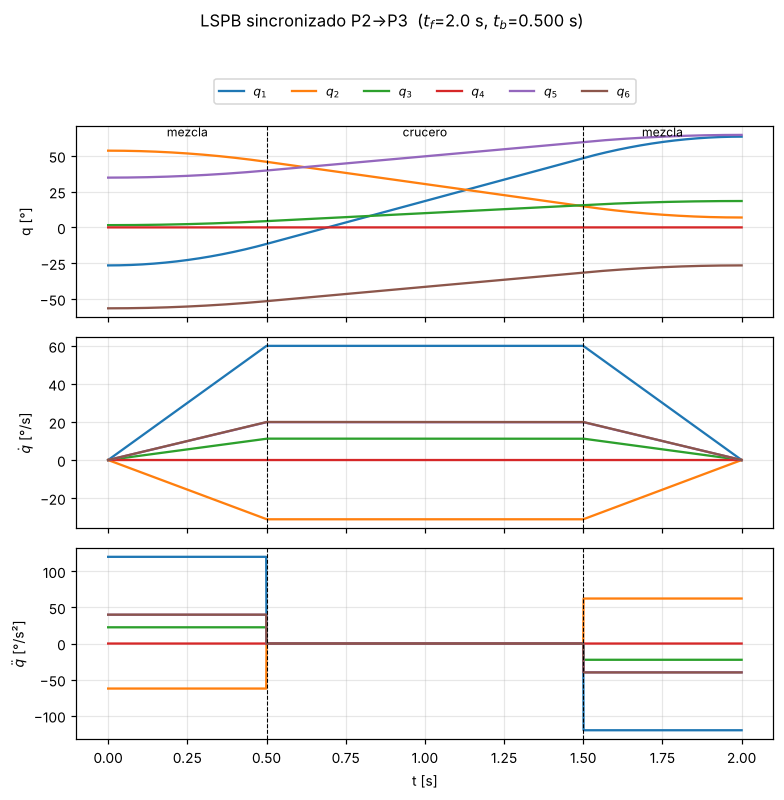

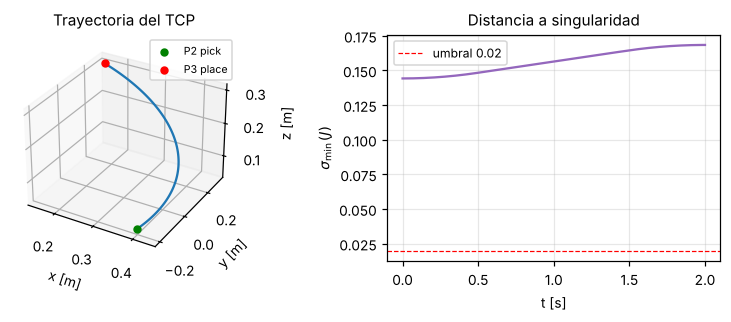

In [ ]:
fig, ax = plt.subplots(3, 1, figsize=(7.2, 7.0), sharex=True)
for i in range(6):
    ax[0].plot(t, np.degrees(Q[:, i]),   color=JOINT_COLORS[i], label=f"$q_{i+1}$")
    ax[1].plot(t, np.degrees(QD[:, i]),  color=JOINT_COLORS[i])
    ax[2].plot(t, np.degrees(QDD[:, i]), color=JOINT_COLORS[i])
for a_ in ax:
    for tj in (TB, TF - TB):
        a_.axvline(tj, color="k", ls="--", lw=0.7)
ax[0].set_ylabel("q [°]"); ax[1].set_ylabel(r"$\dot q$ [°/s]"); ax[2].set_ylabel(r"$\ddot q$ [°/s²]")
ax[2].set_xlabel("t [s]")
ax[0].legend(ncol=6, loc="upper center", bbox_to_anchor=(0.5, 1.28))
ax[0].text(TB/2, ax[0].get_ylim()[1]*0.9, "mezcla", ha="center", fontsize=8)
ax[0].text(TF/2, ax[0].get_ylim()[1]*0.9, "crucero", ha="center", fontsize=8)
ax[0].text(TF-TB/2, ax[0].get_ylim()[1]*0.9, "mezcla", ha="center", fontsize=8)
fig.suptitle(f"LSPB sincronizado P2→P3  ($t_f$={TF:.1f} s, $t_b$={TB:.3f} s)", y=1.03)
fig.tight_layout(); savefig(fig, "lspb_perfiles"); plt.show()

# Trayectoria resultante del TCP (en espacio articular no es una recta)
P_tcp = np.array([fk(q)[:3, 3] for q in Q[::20]])
fig = plt.figure(figsize=(7.2, 3.0))
ax1 = fig.add_subplot(1, 2, 1, projection="3d")
ax1.plot(*P_tcp.T, color="#1f77b4"); ax1.scatter(*P_tcp[0], color="g", label="P2 pick"); ax1.scatter(*P_tcp[-1], color="r", label="P3 place")
ax1.set_xlabel("x [m]"); ax1.set_ylabel("y [m]"); ax1.set_zlabel("z [m]"); ax1.legend(fontsize=7); ax1.set_title("Trayectoria del TCP")
ax2 = fig.add_subplot(1, 2, 2)
ax2.plot(t[::10], smin_traj, color="#9467bd"); ax2.axhline(SMIN_SEL, color="r", ls="--", lw=0.8, label="umbral 0.02")
ax2.set_xlabel("t [s]"); ax2.set_ylabel(r"$\sigma_{\min}(J)$"); ax2.set_title("Distancia a singularidad"); ax2.legend()
fig.tight_layout(); savefig(fig, "lspb_tcp_sigma"); plt.show()

**Interpretación.** Los seis ejes empiezan y terminan simultáneamente en reposo ($\dot q=0$). La posición es $C^1$ (parábola–recta–parábola): $q$ y $\dot q$ son continuas y $\ddot q$ es constante a tramos con saltos finitos en $t_b$ y $t_f-t_b$, lo cual es la propiedad esperada del LSPB. El eje crítico (mayor $|\Delta q|/\dot q_{\max}$, impreso arriba: la rotación de la base de *pick* a *place*) define $t_f$ y es el único que llega al 25 % de su velocidad máxima; los demás se “estiran” para sincronizarse. Como la interpolación es articular, el TCP describe una curva (no una recta), y $\sigma_{\min}$ se mantiene lejos de cero en todo el trayecto: el movimiento está libre de singularidades.

## 5. Jacobiano geométrico $\dot x = J(q)\,\dot q$

Para articulaciones rotacionales, la columna $i$ es la contribución de girar el eje $z_{i-1}$:

$$
J_i(q)=\begin{bmatrix} z_{i-1}\times(p_{TCP}-o_{i-1})\\ z_{i-1}\end{bmatrix},\qquad
\dot x=\begin{bmatrix} v\\ \omega\end{bmatrix}=J(q)\,\dot q,\qquad J\in\mathbb R^{6\times6}.
$$

* Parte superior: velocidad lineal que produce el giro del eje $i$ (brazo de palanca $p_{TCP}-o_{i-1}$).
* Parte inferior: velocidad angular (dirección del eje).

**Validaciones:** (1) contra diferencias finitas centradas de la FK; (2) a lo largo del LSPB: $J(q(t))\dot q(t)$ debe coincidir con la derivada numérica de la pose del TCP.

In [ ]:
def vee(S):
    return np.array([S[2, 1], S[0, 2], S[1, 0]])

def jacobian_numeric(q, h=1e-6):
    Jn, R = np.zeros((6, 6)), fk(q)[:3, :3]
    for i in range(6):
        dq_ = np.zeros(6); dq_[i] = h
        Tp, Tm = fk(q + dq_), fk(q - dq_)
        Jn[:3, i] = (Tp[:3, 3] - Tm[:3, 3]) / (2*h)
        Jn[3:, i] = vee(((Tp[:3, :3] - Tm[:3, :3]) / (2*h)) @ R.T)   # ω^ = Ṙ Rᵀ
    return Jn

# (1) Validación puntual en las configuraciones seleccionadas
for name, sel in SELECTED.items():
    e = np.abs(jacobian(sel["q"]) - jacobian_numeric(sel["q"])).max()
    print(f"{name}: max|J_geom - J_numérico| = {e:.1e}")

# (2) Validación a lo largo del LSPB: v = J qd  vs  d p_TCP/dt
idx = np.arange(0, len(t), 25)
v_J   = np.array([jacobian(Q[k]) @ QD[k] for k in idx])
P_all = np.array([fk(Q[k])[:3, 3] for k in range(len(t))])
v_num = np.gradient(P_all, DT, axis=0)[idx]
print(f"\nLSPB: max|v_J - v_num| = {np.abs(v_J[:, :3] - v_num).max():.1e} m/s   (pico |v_TCP| = {np.linalg.norm(v_J[:, :3], axis=1).max():.3f} m/s)")

P1: max|J_geom - J_numérico| = 7.7e-11
P2: max|J_geom - J_numérico| = 5.4e-11
P3: max|J_geom - J_numérico| = 1.2e-10
P4: max|J_geom - J_numérico| = 6.5e-11

LSPB: max|v_J - v_num| = 4.3e-04 m/s   (pico |v_TCP| = 0.501 m/s)


In [ ]:
# Interpretación de columnas en q0 (P2, pick)
J0 = jacobian(q0)
print("J(q0) =\n", J0.round(4))
print("\nLectura física de columnas en q0:")
for i in range(6):
    v, w = J0[:3, i], J0[3:, i]
    print(f"  col {i+1}: eje z{i} = {w.round(3)};  |v| = {np.linalg.norm(v):.3f} m/rad  (velocidad del TCP por cada rad/s del eje {i+1})")
print("\n• Col 1: ω = z0 = [0,0,1] (giro de la base) y v horizontal: el TCP barre un arco alrededor de z0;")
print("  |v| = distancia horizontal del TCP al eje 1.")
print("• Cols 2 y 3: ω idéntica (ejes 2 y 3 paralelos y horizontales): ambas mueven el TCP en el plano vertical del brazo;")
print("  difieren solo en el brazo de palanca (desde el hombro o desde el codo).")
print("• Col 5: |v| = 0.192 m = d6 + herramienta, la distancia del eje 5 al TCP.")
print("• Col 6: v = 0 porque el TCP está sobre el eje 6: ese eje solo orienta la pinza (rotación pura).")
print("• Col 4: |v| depende de cuánto se aparta el TCP del eje 4 (función de q5).")

J(q0) =
 [[ 0.2    -0.2147 -0.3578  0.049  -0.1717  0.    ]
 [ 0.4     0.1073  0.1789  0.098   0.0859  0.    ]
 [-0.     -0.4472 -0.2298 -0.      0.      0.    ]
 [ 0.      0.4472  0.4472  0.5103  0.4472  0.    ]
 [ 0.      0.8944  0.8944 -0.2552  0.8944 -0.    ]
 [ 1.      0.      0.     -0.8213 -0.     -1.    ]]

Lectura física de columnas en q0:
  col 1: eje z0 = [0. 0. 1.];  |v| = 0.447 m/rad  (velocidad del TCP por cada rad/s del eje 1)
  col 2: eje z1 = [0.447 0.894 0.   ];  |v| = 0.508 m/rad  (velocidad del TCP por cada rad/s del eje 2)
  col 3: eje z2 = [0.447 0.894 0.   ];  |v| = 0.461 m/rad  (velocidad del TCP por cada rad/s del eje 3)
  col 4: eje z3 = [ 0.51  -0.255 -0.821];  |v| = 0.110 m/rad  (velocidad del TCP por cada rad/s del eje 4)
  col 5: eje z4 = [ 0.447  0.894 -0.   ];  |v| = 0.192 m/rad  (velocidad del TCP por cada rad/s del eje 5)
  col 6: eje z5 = [ 0. -0. -1.];  |v| = 0.000 m/rad  (velocidad del TCP por cada rad/s del eje 6)

• Col 1: ω = z0 = [0,0,1] (giro d

## 6. Singularidades: experimento computacional

### 6.1 Resultado analítico
Para esta tabla D-H el determinante se factoriza (se verifica numéricamente abajo):

$$
\det J(q) = -\,a_2\,L\;\underbrace{\sin q_5}_{\text{muñeca}}\;\underbrace{\sin(q_3+\gamma)}_{\text{codo}}\;\underbrace{r_w}_{\text{hombro}}
$$

donde $r_w$ es la distancia (con signo) del centro de muñeca al eje $z_0$. Hay tres familias de singularidad: **muñeca** ($q_5=0$: ejes 4 y 6 colineales), **codo** (brazo totalmente estirado o plegado) y **hombro** (centro de muñeca sobre el eje 1).

El determinante es legítimo aquí porque $J$ es **cuadrada (6×6)**, pero el **criterio central es el rango** obtenido por SVD: $J=U\Sigma V^T$, rango $=\#\{\sigma_i>\text{tol}\}$. El rango dice **cuántas** direcciones se pierden, $u_6$ (columna de $U$) dice **qué velocidad del TCP** se vuelve imposible y $v_6$ (columna de $V$) qué movimiento articular ya no mueve el TCP. El determinante solo dice “cero o no cero” y su magnitud depende de las unidades.

### 6.2 Experimento 1 — aproximación a la singularidad de muñeca ($q_5\to0$)
Secuencia de poses $T_d^{(k)}$ obtenidas a partir de la configuración de *pick* $q^\star(P2)$, haciendo $q_5\in\{45°,30°,\ldots,0.1°,0°\}$. Cada pose se **resuelve con Pieper** (pipeline completo), se selecciona la rama continua y se evalúa $J$.

In [ ]:
# Verificación numérica de la factorización del determinante
rng = np.random.default_rng(7); ratios = []
for _ in range(200):
    q = rng.uniform(Q_MIN, Q_MAX)
    pw = fk_frames(q)[4][:3, 3]
    r_w = pw[0]*np.cos(q[0]) + pw[1]*np.sin(q[0])
    ratios.append(np.linalg.det(jacobian(q)) / (-A2*L_FA*np.sin(q[4])*np.sin(q[2] + GAMMA)*r_w))
print(f"det J / (-a2 L s5 sin(q3+γ) r_w):  min = {min(ratios):.12f},  max = {max(ratios):.12f}")

det J / (-a2 L s5 sin(q3+γ) r_w):  min = 1.000000000000,  max = 1.000000000000


In [ ]:
TOL_RANK = 1e-6
q5_seq = np.radians([45, 30, 20, 10, 5, 2, 1, 0.5, 0.1, 0.0])
q_base = q0.copy()
xdot_lost = None
rows = []
q_prev = q_base.copy()
for q5 in q5_seq:
    q_k = q_base.copy(); q_k[4] = q5
    Td_k = fk(q_k)                                            # pose objetivo de la secuencia
    sols = [c["q"] for c in ik_pieper(Td_k) if c["q"] is not None]
    q_ik = min(sols, key=lambda s: np.linalg.norm(wrap(s - q_prev)))  # rama continua
    q_prev = q_ik
    ep, eR = pose_errors(q_ik, Td_k)
    J = jacobian(q_ik)
    U, S, Vt = np.linalg.svd(J)
    rows.append(dict(q5=q5, q=q_ik, S=S, rank=int(np.sum(S > TOL_RANK)), det=np.linalg.det(J),
                     cond=S[0]/S[-1] if S[-1] > 0 else np.inf, ep=ep, eR=eR, U=U, Vt=Vt, J=J))

# Dirección de prueba: la velocidad del TCP que se pierde en la singularidad (u6 en q5=0)
u_lost = rows[-1]["U"][:, -1]
print(f"{'q5 [°]':>7}{'rango':>6}{'σ1':>8}{'σ5':>8}{'σ6':>11}{'det J':>12}{'κ(J)':>11}{'|q̇| para ẋ=u6':>16}{'e_p IK':>9}")
for r in rows:
    if r["rank"] == 6:
        qd_req = np.linalg.solve(r["J"], u_lost); r["qd_norm"] = np.linalg.norm(qd_req)
        qd_txt = f"{r['qd_norm']:16.1f}"
    else:
        r["qd_norm"] = np.inf; qd_txt = f"{'∞ (sin solución)':>16}"
    print(f"{np.degrees(r['q5']):7.1f}{r['rank']:>6}{r['S'][0]:8.3f}{r['S'][4]:8.3f}{r['S'][5]:11.2e}{r['det']:12.2e}{r['cond']:11.1e}{qd_txt}{r['ep']:9.1e}")

 q5 [°] rango      σ1      σ5         σ6       det J       κ(J)  |q̇| para ẋ=u6   e_p IK
   45.0     6   1.828   0.311   1.44e-01   -2.59e-02    1.3e+01             3.1  2.0e-16
   30.0     6   1.847   0.231   1.44e-01   -1.83e-02    1.3e+01             4.3  2.0e-16
   20.0     6   1.859   0.154   1.45e-01   -1.25e-02    1.3e+01             6.4  2.1e-16
   10.0     6   1.869   0.145   7.40e-02   -6.37e-03    2.5e+01            13.5  2.1e-16
    5.0     6   1.874   0.145   3.59e-02   -3.20e-03    5.2e+01            27.8  2.2e-16
    2.0     6   1.876   0.146   1.41e-02   -1.28e-03    1.3e+02            71.1  2.1e-16
    1.0     6   1.877   0.146   6.98e-03   -6.40e-04    2.7e+02           143.3  2.1e-16
    0.5     6   1.878   0.146   3.47e-03   -3.20e-04    5.4e+02           287.8  2.1e-16
    0.1     6   1.878   0.146   6.93e-04   -6.40e-05    2.7e+03          1443.3  1.8e-16
    0.0     5   1.878   0.146   1.20e-16   -2.71e-18    1.6e+16∞ (sin solución)  2.1e-16


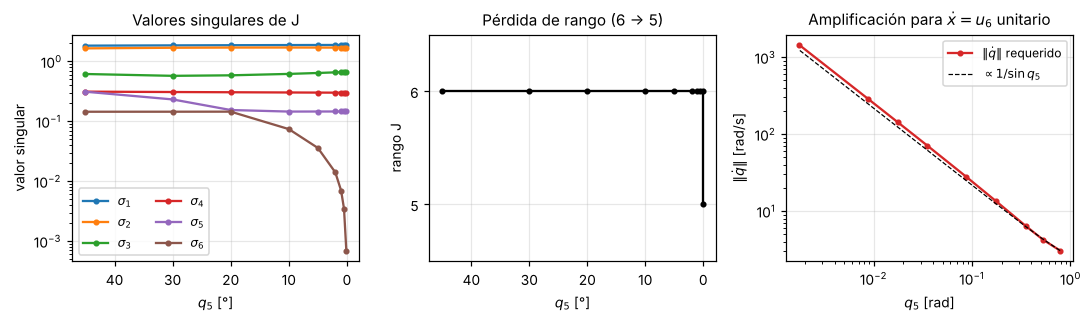

In [ ]:
q5d = np.degrees([r["q5"] for r in rows])
S_all = np.array([r["S"] for r in rows])
fig, ax = plt.subplots(1, 3, figsize=(10, 3.0))
for i in range(6):
    ax[0].semilogy(q5d[:-1], S_all[:-1, i], "o-", ms=3, label=fr"$\sigma_{i+1}$")
ax[0].invert_xaxis(); ax[0].set_xlabel(r"$q_5$ [°]"); ax[0].set_ylabel("valor singular"); ax[0].set_title("Valores singulares de J"); ax[0].legend(ncol=2)
ax[1].step(q5d, [r["rank"] for r in rows], where="mid", color="k"); ax[1].plot(q5d, [r["rank"] for r in rows], "ko", ms=3)
ax[1].set_ylim(4.5, 6.5); ax[1].set_yticks([5, 6]); ax[1].invert_xaxis(); ax[1].set_xlabel(r"$q_5$ [°]"); ax[1].set_ylabel("rango J"); ax[1].set_title("Pérdida de rango (6 → 5)")
qn = np.array([r["qd_norm"] for r in rows[:-1]])
ax[2].loglog(np.radians(q5d[:-1]), qn, "o-", color="#d62728", ms=3, label=r"$\|\dot q\|$ requerido")
ax[2].loglog(np.radians(q5d[:-1]), qn[0]*np.sin(np.radians(q5d[0]))/np.sin(np.radians(q5d[:-1])), "k--", lw=0.8, label=r"$\propto 1/\sin q_5$")
ax[2].set_xlabel(r"$q_5$ [rad]"); ax[2].set_ylabel(r"$\|\dot q\|$ [rad/s]"); ax[2].set_title(r"Amplificación para $\dot x=u_6$ unitario"); ax[2].legend()
fig.tight_layout(); savefig(fig, "singularidad_aproximacion"); plt.show()

In [ ]:
# Interpretación de la movilidad perdida en q5 = 0
rs = rows[-1]
u6, v6 = rs["U"][:, -1], rs["Vt"][-1, :]
F = fk_frames(rs["q"])
z3, z5 = F[3][:3, 2], F[5][:3, 2]
print("En q5 = 0:")
print(f"  eje 4 (z3) = {z3.round(4)}   eje 6 (z5) = {z5.round(4)}   -> |z3 x z5| = {np.linalg.norm(np.cross(z3, z5)):.1e}  (colineales)")
print(f"  Espacio nulo v6 (q̇ que NO mueve el TCP) = {v6.round(4)}  -> q̇4 = -q̇6: los ejes 4 y 6 se cancelan")
print(f"  |J v6| = {np.linalg.norm(rs['J'] @ v6):.1e}")
print(f"  Dirección perdida u6 (ẋ imposible) = v: {u6[:3].round(4)}  ω: {u6[3:].round(4)}")
w_dir = u6[3:] / np.linalg.norm(u6[3:])
print(f"  ω perdida ⟂ eje 4: {abs(w_dir @ z3):.1e}, ⟂ eje 5 (z4): {abs(w_dir @ F[4][:3, 2]):.1e}")
print("  -> El TCP no puede girar alrededor del eje perpendicular simultáneamente a los ejes 4/6 y al eje 5:")
print("     la muñeca pasa de 3 a 2 grados de libertad rotacionales efectivos.")

En q5 = 0:
  eje 4 (z3) = [ 0.5103 -0.2552 -0.8213]   eje 6 (z5) = [ 0.5103 -0.2552 -0.8213]   -> |z3 x z5| = 0.0e+00  (colineales)
  Espacio nulo v6 (q̇ que NO mueve el TCP) = [-0.     -0.      0.      0.7071  0.     -0.7071]  -> q̇4 = -q̇6: los ejes 4 y 6 se cancelan
  |J v6| = 2.0e-16
  Dirección perdida u6 (ẋ imposible) = v: [-0.3201 -0.6401  0.    ]  ω: [ 0.513  -0.2565  0.3985]
  ω perdida ⟂ eje 4: 4.4e-17, ⟂ eje 5 (z4): 4.7e-17
  -> El TCP no puede girar alrededor del eje perpendicular simultáneamente a los ejes 4/6 y al eje 5:
     la muñeca pasa de 3 a 2 grados de libertad rotacionales efectivos.


### 6.3 Experimento 2 — recta cartesiana que pasa cerca de $q_5=0$ (pasaporte del PFI)

El TCP recorre una recta $y\in[-0.15,\,0.15]$ m a velocidad constante $0.075$ m/s, con la orientación de la posición de calibración ($z_{TCP}$ horizontal hacia $+x_0$), a una distancia vertical $\delta$ de la configuración singular $q=0$. Cada punto se resuelve con **Pieper** (rama continua) y se compara la velocidad articular obtenida por $\dot q=J^{-1}\dot x$ con la derivada numérica de la IK.

In [ ]:
def cart_line(delta, v=0.075, y0=-0.15, y1=0.15, dt=5e-4):
    T_home = fk(np.zeros(6))
    n = int(round((y1 - y0)/v/dt)) + 1
    tt = np.linspace(0, (y1 - y0)/v, n)
    xdot = np.array([0, v, 0, 0, 0, 0])
    qs, qds, smins = [], [], []
    q_prev = np.zeros(6)
    for ti in tt:
        Td = T_home.copy(); Td[:3, 3] += [-0.02, y0 + v*ti, -delta]
        sols = [c["q"] for c in ik_pieper(Td) if c["q"] is not None]
        q = min(sols, key=lambda s: np.linalg.norm(wrap(s - q_prev)))
        q = q_prev + wrap(q - q_prev)                     # continuidad angular
        q_prev = q
        J = jacobian(q)
        qs.append(q); qds.append(np.linalg.solve(J, xdot)); smins.append(np.linalg.svd(J, compute_uv=False)[-1])
    qs, qds = np.array(qs), np.array(qds)
    return tt, qs, qds, np.array(smins), np.gradient(qds, tt, axis=0)

LINE = {}
for delta in (0.02, 0.005, 0.001):
    tt, qs, qds, sm, qdds = cart_line(delta)
    e_vel = np.abs(np.gradient(qs, tt, axis=0) - qds)[2:-2].max() / np.abs(qds).max()
    LINE[delta] = (tt, qs, qds, sm, qdds)
    print(f"δ = {1000*delta:4.1f} mm: q5_min = {np.degrees(np.abs(qs[:,4]).min()):6.3f}°,  σmin = {sm.min():.2e},  "
          f"max|q̇4| = {np.abs(qds[:,3]).max():7.2f} rad/s ({100*np.abs(qds[:,3]).max()/QD_MAX[3]:6.0f} % Vmax),  "
          f"max|q̈4| = {np.abs(qdds[:,3]).max():9.1f} rad/s²,  error relativo J⁻¹ẋ vs dq/dt = {e_vel:.1e}")

δ = 20.0 mm: q5_min =  3.572°,  σmin = 1.12e-02,  max|q̇4| =    4.27 rad/s (    76 % Vmax),  max|q̈4| =      11.9 rad/s²,  error relativo J⁻¹ẋ vs dq/dt = 1.5e-06


δ =  5.0 mm: q5_min =  0.793°,  σmin = 2.49e-03,  max|q̇4| =   19.21 rad/s (   344 % Vmax),  max|q̈4| =     240.0 rad/s²,  error relativo J⁻¹ẋ vs dq/dt = 3.1e-05


δ =  1.0 mm: q5_min =  0.048°,  σmin = 1.51e-04,  max|q̇4| =  316.41 rad/s (  5665 % Vmax),  max|q̈4| =   63614.3 rad/s²,  error relativo J⁻¹ẋ vs dq/dt = 8.2e-03


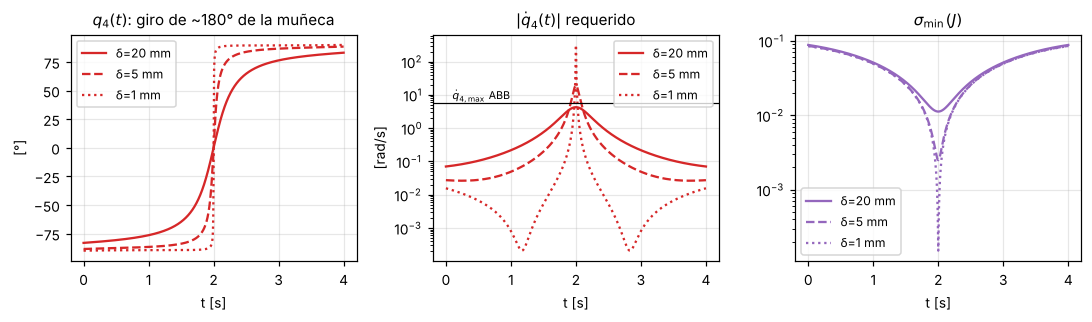

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(10, 3.0))
for (delta, (tt, qs, qds, sm, qdds)), ls in zip(LINE.items(), ["-", "--", ":"]):
    lab = f"δ={1000*delta:g} mm"
    ax[0].plot(tt, np.degrees(qs[:, 3]), ls, color="#d62728", label=lab)
    ax[1].semilogy(tt, np.abs(qds[:, 3]), ls, color="#d62728", label=lab)
    ax[2].semilogy(tt, sm, ls, color="#9467bd", label=lab)
ax[1].axhline(QD_MAX[3], color="k", lw=0.8); ax[1].text(0.1, QD_MAX[3]*1.3, r"$\dot q_{4,\max}$ ABB", fontsize=7)
ax[0].set_title(r"$q_4(t)$: giro de ~180° de la muñeca"); ax[0].set_ylabel("[°]")
ax[1].set_title(r"$|\dot q_4(t)|$ requerido"); ax[1].set_ylabel("[rad/s]")
ax[2].set_title(r"$\sigma_{\min}(J)$");
for a_ in ax: a_.set_xlabel("t [s]"); a_.legend()
fig.tight_layout(); savefig(fig, "singularidad_recta"); plt.show()

**Interpretación del experimento de singularidad**

* **Pérdida de rango:** al llegar a $q_5=0$ el rango cae de 6 a 5 ($\sigma_6\to0$, $\sigma_1\ldots\sigma_5$ casi constantes) y $\det J\propto\sin q_5\to0$. Los ejes 4 y 6 quedan colineales: el movimiento $\dot q_4=-\dot q_6$ (espacio nulo $v_6$) no mueve el TCP, y existe una velocidad del TCP ($u_6$) que ningún $\dot q$ puede producir → se pierde **un grado de movilidad local**.
* **Amplificación de velocidad:** cerca de la singularidad, $\dot q=J^{-1}\dot x=\sum_i \frac{u_i^T\dot x}{\sigma_i}v_i$; la componente de $\dot x$ sobre $u_6$ se divide por $\sigma_6\sim\sin q_5$, por eso $\|\dot q\|\propto 1/\sin q_5$ (pendiente −1 en escala log-log). En la recta cartesiana, con solo 0.075 m/s en el TCP, el eje 4 debe girar ~180° en un instante: con $\delta=1$ mm se exceden varias veces los 320 °/s del IRB 120.
* **¿Torque infinito? No por la cinemática.** La relación estática es $\tau=J^T F$ y $J^T$ permanece **acotada** en la singularidad (sus elementos son distancias y cosenos). Lo que diverge es la **velocidad y aceleración articular exigidas** si se insiste en seguir una trayectoria cartesiana; el torque solo crece de forma indirecta a través del término inercial $J_{eq}\ddot q$ (sección 7). En una singularidad la estructura incluso **soporta** fuerzas en la dirección perdida sin torque de motor.
* **Consecuencia de diseño:** la trayectoria del proyecto se planifica en espacio articular (LSPB) entre configuraciones con $\sigma_{\min}>0.02$ y se vigila $\sigma_{\min}$ a lo largo del movimiento.

## 7. Dinámica reducida 1R y torque $\tau(t)$ sobre el LSPB

### 7.1 Modelo
Se usa el modelo 1R de clase aplicado al **eje 2** (hombro, el eje que sostiene el brazo contra la gravedad):

$$
\tau(t)=\underbrace{J\,\ddot\theta(t)}_{\tau_{\text{inercial}}}+\underbrace{m\,g\,\ell_c\,\sin\theta(t)}_{\tau_{\text{gravedad}}},
\qquad J=m\,\ell_c^{2}\ \ (\text{masa puntual}).
$$

$\theta$ se mide desde la **vertical hacia abajo** (péndulo), en el mismo sentido positivo que $q_2$. Como en $q_2=0$ el brazo apunta hacia arriba, $\theta=\pi+q_2+\delta_0$, con $\delta_0$ el ángulo entre el brazo superior y la recta eje 2 → TCP (eslabón rígido equivalente congelado en $q_0$). Por lo tanto $\ddot\theta=\ddot q_2$, que viene directamente del LSPB.

### 7.2 Parámetros y procedencia
| Parámetro | Valor | Procedencia |
|---|---|---|
| $m$ | 3.0 kg | Carga útil nominal del IRB 120 (“3 kg”, ABB 3HAC035960-005). Se modela la pieza + pinza en el TCP como el peor caso permitido. |
| $\ell_c$ | distancia eje 2 → TCP en $q_0$ | Calculada con la FK del Hito 1 (no inventada) |
| $\delta_0$ | ángulo brazo–(eje 2→TCP) en $q_0$ | Calculado con la FK |
| $g$ | 9.81 m/s² | |

**Supuesto declarado:** ABB **no publica** masas ni inercias por eslabón (solo la masa total del robot, ~25 kg). Por eso **no** se incluye el peso propio del brazo: $\tau(t)$ representa el **torque adicional en el eje 2 debido a la carga útil**, no el torque total del motor. Tampoco se modelan fricción ni la inercia reflejada del reductor.

In [ ]:
M_PAYLOAD, G = 3.0, 9.81

def j2_to_tcp_planar(q):
    # Coordenadas (r, z) del TCP respecto al eje 2, en el plano vertical del brazo
    F = fk_frames(q)
    d = (F[-1] @ T_6_TCP)[:3, 3] - F[1][:3, 3]          # vector eje2 -> TCP
    r = d[0]*np.cos(q[0]) + d[1]*np.sin(q[0])            # componente horizontal sobre x1
    return r, d[2]

r0, z0 = j2_to_tcp_planar(q0)
L_C = np.hypot(r0, z0)
DELTA0 = np.arctan2(r0, z0) - q0[1]
J_1R = M_PAYLOAD * L_C**2
print(f"ℓc = {L_C:.4f} m,  δ0 = {np.degrees(DELTA0):.2f}°,  J = m ℓc² = {J_1R:.4f} kg·m²")

theta    = np.pi + Q[:, 1] + DELTA0
thetadd  = QDD[:, 1]
tau_in   = J_1R * thetadd
tau_g    = M_PAYLOAD * G * L_C * np.sin(theta)
tau      = tau_in + tau_g

# Validación 1: en reposo (t = 0) el término de gravedad 1R debe igualar el torque estático exacto
#               del eje 2 dado por el Jacobiano: τ = J_vᵀ F, con F = (0, 0, m g) (fuerza que sostiene la carga)
F_hold = np.array([0, 0, M_PAYLOAD*G])
tau_exact = np.array([(jacobian(q)[:3, :].T @ F_hold)[1] for q in Q])
print(f"t=0:  τ_g(1R) = {tau_g[0]:.4f} N·m   vs   (J_vᵀF)_2 = {tau_exact[0]:.4f} N·m")
print(f"A lo largo del LSPB: máx |τ_g(1R) - (J_vᵀF)_2| = {np.abs(tau_g - tau_exact).max():.3f} N·m "
      f"(error del eslabón rígido equivalente: q3..q6 no quedan congelados, Δq3 = {np.degrees(dq[2]):.1f}°, Δq5 = {np.degrees(dq[4]):.1f}°)")

# Validación 2: τ_in integra a cero (acelera y frena con la misma |a|)
print(f"∫ τ_in dt = {np.trapezoid(tau_in, t) if hasattr(np, 'trapezoid') else np.trapz(tau_in, t):.2e} N·m·s")

k_max = np.argmax(np.abs(tau))
print(f"\nPico |τ| = {abs(tau[k_max]):.3f} N·m en t = {t[k_max]:.3f} s  "
      f"(τ_g = {tau_g[k_max]:.3f}, τ_in = {tau_in[k_max]:.3f});  |τ_in|máx = {np.abs(tau_in).max():.3f} N·m,  |τ_g|máx = {np.abs(tau_g).max():.3f} N·m")

ℓc = 0.5075 m,  δ0 = 64.58°,  J = m ℓc² = 0.7728 kg·m²


t=0:  τ_g(1R) = -13.1615 N·m   vs   (J_vᵀF)_2 = -13.1615 N·m
A lo largo del LSPB: máx |τ_g(1R) - (J_vᵀF)_2| = 4.294 N·m (error del eslabón rígido equivalente: q3..q6 no quedan congelados, Δq3 = 16.9°, Δq5 = 29.9°)
∫ τ_in dt = -5.55e-17 N·m·s

Pico |τ| = 14.937 N·m en t = 1.156 s  (τ_g = -14.937, τ_in = 0.000);  |τ_in|máx = 0.840 N·m,  |τ_g|máx = 14.937 N·m


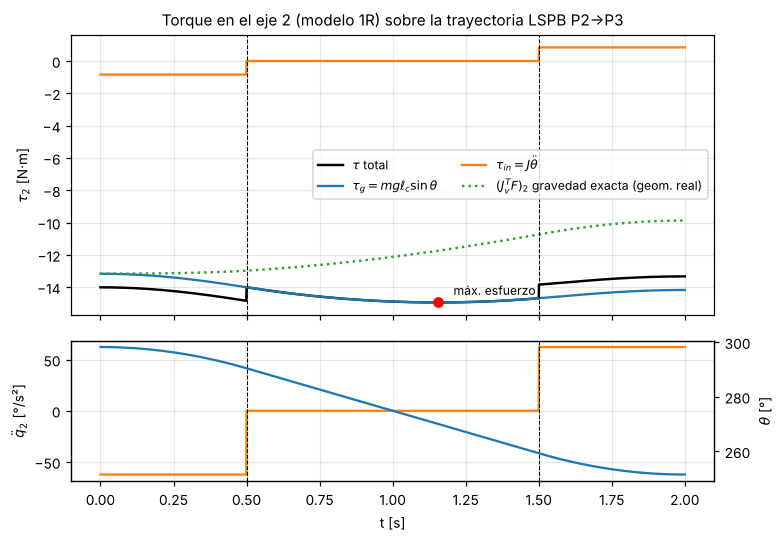

 mezcla inicial: |τ| máx = 14.834 N·m, τ_in = -0.840 N·m -> la inercia SUMA a la gravedad
        crucero: |τ| máx = 14.937 N·m, τ_in = +0.000 N·m -> la inercia no afecta a la gravedad
   mezcla final: |τ| máx = 13.835 N·m, τ_in = +0.840 N·m -> la inercia RESTA a la gravedad
Máximo esfuerzo en t = 1.156 s con θ = 270.0° (brazo de palanca horizontal ℓc|sin θ| = 0.508 m de 0.508 m posibles)


In [ ]:
fig, ax = plt.subplots(2, 1, figsize=(7.2, 5.0), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
ax[0].plot(t, tau, "k", lw=1.6, label=r"$\tau$ total")
ax[0].plot(t, tau_g, color="#1f77b4", label=r"$\tau_g = mg\ell_c\sin\theta$")
ax[0].plot(t, tau_in, color="#ff7f0e", label=r"$\tau_{in} = J\ddot\theta$")
ax[0].plot(t, tau_exact, ":", color="#2ca02c", lw=1.6, label=r"$(J_v^TF)_2$ gravedad exacta (geom. real)")
ax[0].plot(t[k_max], tau[k_max], "ro"); ax[0].annotate("máx. esfuerzo", (t[k_max], tau[k_max]), textcoords="offset points", xytext=(10, 5), fontsize=8)
ax[0].set_ylabel(r"$\tau_2$ [N·m]"); ax[0].legend(ncol=2); ax[0].set_title("Torque en el eje 2 (modelo 1R) sobre la trayectoria LSPB P2→P3")
ax[1].plot(t, np.degrees(QDD[:, 1]), color="#ff7f0e", label=r"$\ddot q_2$ [°/s²]")
ax1b = ax[1].twinx(); ax1b.plot(t, np.degrees(theta), color="#1f77b4", label=r"$\theta$ [°]"); ax1b.grid(False)
ax[1].set_ylabel(r"$\ddot q_2$ [°/s²]"); ax1b.set_ylabel(r"$\theta$ [°]"); ax[1].set_xlabel("t [s]")
for a_ in ax:
    for tj in (TB, TF - TB): a_.axvline(tj, color="k", ls="--", lw=0.7)
fig.tight_layout(); savefig(fig, "torque_1R"); plt.show()

# Lectura automática de las fases (se actualiza si cambian las poses)
fases = {"mezcla inicial": t < TB, "crucero": (t >= TB) & (t <= TF - TB), "mezcla final": t > TF - TB}
for nombre, m_ in fases.items():
    rel = "SUMA a" if np.mean(np.sign(tau_in[m_]) == np.sign(tau_g[m_])) > 0.5 and np.abs(tau_in[m_]).max() > 0 else (
          "RESTA a" if np.abs(tau_in[m_]).max() > 0 else "no afecta a")
    print(f"{nombre:>15}: |τ| máx = {np.abs(tau[m_]).max():6.3f} N·m, τ_in = {tau_in[m_].mean():+.3f} N·m -> la inercia {rel} la gravedad")
print(f"Máximo esfuerzo en t = {t[k_max]:.3f} s con θ = {np.degrees(theta[k_max]) % 360:.1f}° "
      f"(brazo de palanca horizontal ℓc|sin θ| = {L_C*abs(np.sin(theta[k_max])):.3f} m de {L_C:.3f} m posibles)")

In [ ]:
# Sensibilidad: ¿cuándo deja de dominar la gravedad? El término inercial escala con 1/t_f²
print(f"{'t_f [s]':>8}{'%Vmax eje crítico':>19}{'|τ_in|máx [N·m]':>17}{'|τ|máx [N·m]':>14}{'τ_in/τ_g':>10}")
for tf_s in (TF, 1.2, 0.8, 0.6, 0.45):
    tb_s = KAPPA*tf_s
    tt_s = np.linspace(0, tf_s, 2001)
    Qs, QDs, QDDs = lspb(tt_s, q0, qf, tf_s, tb_s)
    ti = J_1R*QDDs[:, 1]; tg = M_PAYLOAD*G*L_C*np.sin(np.pi + Qs[:, 1] + DELTA0)
    pv = 100*np.max(np.abs(QDs[:, i_crit]))/QD_MAX[i_crit]
    print(f"{tf_s:8.2f}{pv:18.0f}%{np.abs(ti).max():17.3f}{np.abs(ti+tg).max():14.3f}{np.abs(ti).max()/np.abs(tg).max():10.2f}")
print(f"(con t_f < {abs(dq[i_crit])/((1-KAPPA)*QD_MAX[i_crit]):.2f} s el eje crítico excedería su velocidad máxima ABB)")

 t_f [s]  %Vmax eje crítico  |τ_in|máx [N·m]  |τ|máx [N·m]  τ_in/τ_g
    2.00                24%            0.840        14.937      0.06
    1.20                40%            2.334        16.328      0.16
    0.80                60%            5.251        19.245      0.35
    0.60                80%            9.335        23.330      0.62
    0.45               107%           16.596        30.590      1.11
(con t_f < 0.48 s el eje crítico excedería su velocidad máxima ABB)


**Interpretación de $\tau(t)$**

* **Fase de mezcla inicial ($0<t<t_b$):** $\ddot q_2$ es constante, así que $\tau_{in}$ es un escalón; el esfuerzo total es la suma de sostener la carga y acelerarla.
* **Crucero ($t_b<t<t_f-t_b$):** $\ddot q_2=0\Rightarrow\tau_{in}=0$; el torque es **puramente gravitacional** y varía con $\sin\theta$, es decir, con el brazo de palanca horizontal de la carga respecto al eje 2.
* **Mezcla final:** $\tau_{in}$ cambia de signo (frenado).
* **Región de mayor esfuerzo:** donde el brazo de palanca horizontal de la carga es máximo ($\theta\approx270^\circ$, $|\sin\theta|=1$), y en la mezcla en la que la aceleración tiene el mismo signo que la gravedad (la lectura automática de arriba identifica ambas para las poses actuales). Con 3 kg y velocidades al 25 % de Vmax **la gravedad domina** ($\tau_{in}/\tau_g\approx6\,\%$); la tabla de sensibilidad muestra que $\tau_{in}\propto1/t_f^2$ y se iguala a la gravedad recién cerca de la velocidad máxima del robot.
* **Validación:** el término gravitacional 1R coincide con $(J_v^TF)_2$ exacto en $t=0$; la diferencia posterior (curva punteada) cuantifica el error del modelo reducido: el 1R congela la geometría, mientras que en el robot real $q_3$ y la muñeca se mueven y cambian el brazo de palanca.

**Degradación cinemática vs. comportamiento dinámico**

| | Singularidad (sección 6) | Dinámica 1R (sección 7) |
|---|---|---|
| Qué la produce | Geometría: $\operatorname{rango}J<6$ | Masa, inercia, gravedad y aceleración |
| Variable afectada | Relación $\dot x\leftrightarrow\dot q$ (velocidades) | Torque $\tau$ para seguir $q(t)$ |
| Síntoma | $\dot q\to\infty$ para ciertas $\dot x$; pérdida de 1 GDL | Picos de $\tau$ en zonas de aceleración y gran brazo de palanca |
| Depende de la trayectoria temporal | No (es una propiedad de la configuración) | Sí ($\tau_{in}\propto\ddot q$) |
| Mitigación | Evitar $\sigma_{\min}\to0$ al planificar | Ajustar $t_f$, $t_b$; limitar carga |

Una configuración puede ser singular con torque estático pequeño, y una trayectoria lejos de singularidades puede exigir mucho torque si es muy rápida: son fenómenos **distintos**.

## 8. Resumen de resultados (exportado para el informe IEEE)

In [ ]:
summary = {
    "poses": {k: {"p": POSES[k][:3, 3].round(4).tolist(), "rpy_deg": list(POSES_SPEC[k][1])} for k in POSES},
    "candidatos_reales": int(n_real), "candidatos_validados_fk": int(n_fk), "candidatos_admisibles": int(n_adm),
    "peor_error_pose": float(worst),
    "seleccion": {k: {"rama": v["rama"], "q_deg": np.degrees(v["q"]).round(2).tolist(), "sigma_min": round(float(v["smin"]), 4)} for k, v in SELECTED.items()},
    "lspb": {"tf": TF, "tb": TB, "dq_deg": np.degrees(dq).round(2).tolist(), "V_degs": np.degrees(V_lspb).round(2).tolist(),
             "a_degs2": np.degrees(A_lspb).round(2).tolist(), "smin_min": float(smin_traj.min())},
    "singularidad": [{"q5_deg": float(np.degrees(r["q5"])), "rank": r["rank"], "sigma6": float(r["S"][5]), "det": float(r["det"]),
                      "qd_norm": (float(r["qd_norm"]) if np.isfinite(r["qd_norm"]) else None)} for r in rows],
    "recta": {f"{1000*d:g}mm": {"qd4_max": float(np.abs(v[2][:, 3]).max()), "qdd4_max": float(np.abs(v[4][:, 3]).max()),
                                 "smin": float(v[3].min())} for d, v in LINE.items()},
    "dinamica": {"m": M_PAYLOAD, "lc": float(L_C), "delta0_deg": float(np.degrees(DELTA0)), "J": float(J_1R),
                 "tau_max": float(abs(tau[k_max])), "t_tau_max": float(t[k_max]), "tau_in_max": float(np.abs(tau_in).max()),
                 "tau_g_max": float(np.abs(tau_g).max()), "err_1R_vs_exacto": float(np.abs(tau_g - tau_exact).max())},
}
Path("resultados_hito2.json").write_text(json.dumps(summary, indent=2, ensure_ascii=False))
print(json.dumps(summary["seleccion"], indent=1, ensure_ascii=False))
print("\nFiguras generadas:", sorted(p.name for p in FIG_DIR.glob("*.pdf")))

{
 "P1": {
  "rama": "frente/codo+/s5>0",
  "q_deg": [
   0.0,
   -1.77,
   8.87,
   -0.0,
   82.9,
   0.0
  ],
  "sigma_min": 0.1565
 },
 "P2": {
  "rama": "frente/codo+/s5>0",
  "q_deg": [
   -26.57,
   53.64,
   1.58,
   -0.0,
   34.79,
   -56.57
  ],
  "sigma_min": 0.1442
 },
 "P3": {
  "rama": "frente/codo+/s5>0",
  "q_deg": [
   63.43,
   6.92,
   18.43,
   -0.0,
   64.65,
   -26.57
  ],
  "sigma_min": 0.1684
 },
 "P4": {
  "rama": "frente/codo+/s5>0",
  "q_deg": [
   24.93,
   4.16,
   18.74,
   -34.62,
   45.58,
   10.28
  ],
  "sigma_min": 0.155
 }
}

Figuras generadas: ['lspb_perfiles.pdf', 'lspb_tcp_sigma.pdf', 'singularidad_aproximacion.pdf', 'singularidad_recta.pdf', 'torque_1R.pdf']


## 9. Conclusiones

1. **Pieper** resuelve analíticamente las 8 ramas (hombro × codo × muñeca) usando `atan2`; las poses fuera del alcance se detectan por $|c|>1$ (raíces complejas) y no se fuerzan.
2. **Todos** los candidatos reales se validaron por FK comparando posición y orientación (error ≈ $10^{-16}$), y se filtraron por límites ABB; la selección se justificó por mínimo desplazamiento ponderado, continuidad de rama y margen $\sigma_{\min}$.
3. El **LSPB sincronizado** cumple reposo en las fronteras, continuidad de $q$ y $\dot q$, límites de posición/velocidad, y un $t_f$ compatible con el KPI de ciclo (< 8 s).
4. El **Jacobiano** se validó contra diferencias finitas y contra la derivada numérica de la pose del TCP a lo largo de la trayectoria; $\det J=-a_2L\,s_5\sin(q_3+\gamma)\,r_w$ identifica las tres singularidades.
5. El experimento de **singularidad** muestra la caída de rango 6→5 en $q_5=0$, la dirección perdida y la amplificación $\|\dot q\|\propto1/\sin q_5$; no implica torque estático infinito.
6. El **modelo 1R** muestra que, para esta trayectoria, el esfuerzo del eje 2 está dominado por la gravedad de la carga; el término inercial aparece solo en las mezclas.

**Limitaciones:** sin masas por eslabón publicadas por ABB, el torque calculado corresponde a la carga útil; el modelo 1R congela la geometría del brazo y no captura acoplamientos entre ejes (se cuantificó su error frente a $J^TF$).